# Persistence Length — MUC2 Long PTS
## Glycosylated vs Non-glycosylated

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

base       = "/home/computer2/analysis_simulations/analysis/persistence_length/"
output_dir = "/home/computer2/analysis_simulations/analysis/persistence_length/plots"
os.makedirs(output_dir, exist_ok=True)

CLR_GLY = "#2E86AB"
CLR_NOG = "#A23B72"

print("Ready. Output:", output_dir)

Ready. Output: /home/computer2/analysis_simulations/analysis/persistence_length/plots


## Load Data

In [2]:
# Tangent-tangent correlations (full chain)
gly_dat  = np.genfromtxt(base + "tangent_correlation_glycans.dat",   comments="#")
nog_dat  = np.genfromtxt(base + "tangent_correlation_noglycans.dat", comments="#")
# cols: bond_sep  contour_dist_A  C_mean  C_stderr  C_fitted
s_gly  = gly_dat[:, 1];  C_gly  = gly_dat[:, 2];  Ce_gly  = gly_dat[:, 3];  Cf_gly  = gly_dat[:, 4]
s_nog  = nog_dat[:, 1];  C_nog  = nog_dat[:, 2];  Ce_nog  = nog_dat[:, 3];  Cf_nog  = nog_dat[:, 4]

# Sliding window Lp along the chain
sw_gly  = np.genfromtxt(base + "lp_sliding_window_glycans.dat",   comments="#")
sw_nog  = np.genfromtxt(base + "lp_sliding_window_noglycans.dat", comments="#")
sw_comp = np.genfromtxt(base + "lp_sliding_window_comparison.dat",comments="#")
# cols: window_start  window_centre  Lp_A  Lp_nm  R2
win_centre_gly = sw_gly[:, 1];  Lp_win_gly = sw_gly[:, 2];  R2_win_gly = sw_gly[:, 4]
win_centre_nog = sw_nog[:, 1];  Lp_win_nog = sw_nog[:, 2];  R2_win_nog = sw_nog[:, 4]
delta_Lp_win   = sw_comp[:, 6]  # gly - nog

# Read summary from text file
with open(base + "persistence_length_summary.txt") as f:
    summary = f.read()
print(summary)

# Global Lp values (from summary)
Lp_gly_A  = 191.952;  Lp_nog_A  = 13.206
Lp_gly_nm = 19.195;   Lp_nog_nm = 1.321
ratio = Lp_gly_A / Lp_nog_A
print(f"Ratio Lp(glyc)/Lp(noglyc) = {ratio:.1f}x")

Persistence Length Summary
Long PTS | MUC2 | Residues 1377-1491 | CA only
Mean CA-CA bond length: 3.8570 A
Window size: 30 residues
Window pairs: (1,2) to (27,28)

=== GLOBAL Lp (full 115-residue chain) ===
Glycosylated:     191.952 A  (19.1952 nm)  R2=-5.4290
Non-glycosylated: 13.206 A  (1.3206 nm)  R2=-3.6887

=== SLIDING WINDOW Lp (30-residue windows) ===
Glycosylated     mean: 70.912 A  std: 3.934 A  valid windows: 86/86
Non-glycosylated mean: 13.778 A  std: 0.812 A  valid windows: 86/86
Mean delta (gly - nog): 57.134 A

Ratio Lp(glyc)/Lp(noglyc) = 14.5x


## Figure 1 — Tangent-Tangent Correlation with Exponential Fit

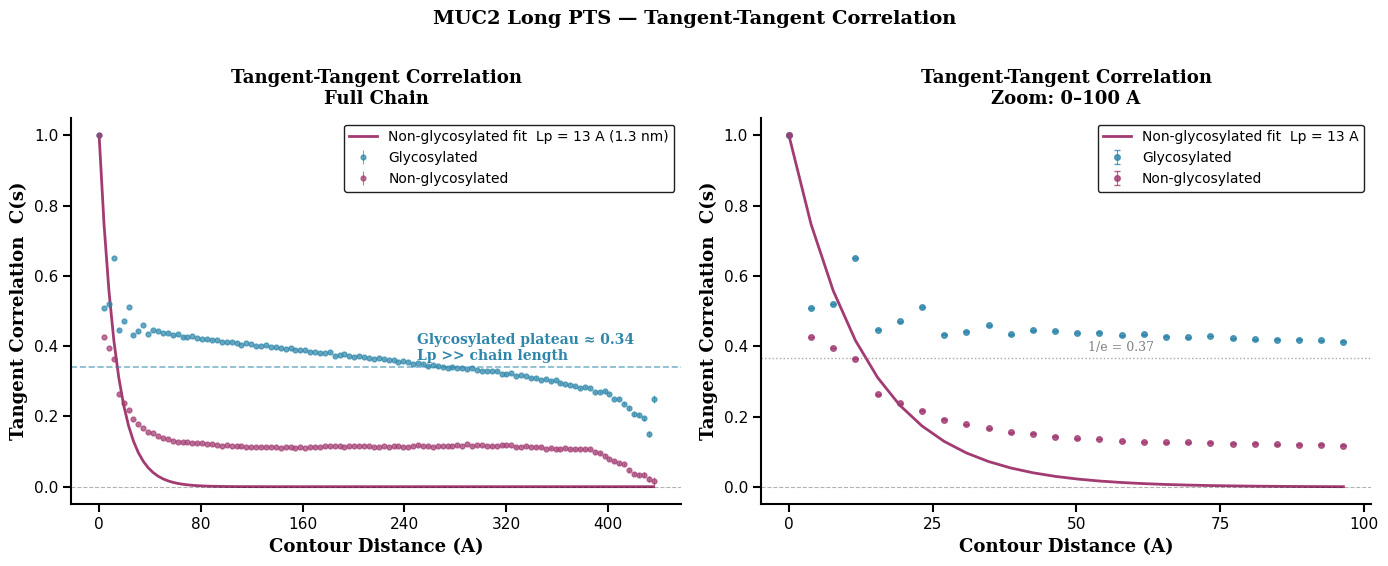

Saved: /home/computer2/analysis_simulations/analysis/persistence_length/plots/tangent_correlation.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=100)
fig.set_facecolor("white")

# ── Left panel: full chain tangent correlation ────────────────────────────────
ax = axes[0]

ax.errorbar(s_gly, C_gly, yerr=Ce_gly,
            fmt="o", color=CLR_GLY, markersize=3.5, alpha=0.7,
            linewidth=0, elinewidth=0.8, capsize=0,
            label=f"Glycosylated")
ax.errorbar(s_nog, C_nog, yerr=Ce_nog,
            fmt="o", color=CLR_NOG, markersize=3.5, alpha=0.7,
            linewidth=0, elinewidth=0.8, capsize=0,
            label=f"Non-glycosylated")

# Fit line only for non-glycosylated (valid fit)
ax.plot(s_nog, Cf_nog, color=CLR_NOG, linewidth=2.0, linestyle="-",
        label=f"Non-glycosylated fit  Lp = {Lp_nog_A:.0f} A ({Lp_nog_nm:.1f} nm)")

# Annotate glycosylated plateau
plateau_val = float(np.mean(C_gly[20:]))
ax.axhline(plateau_val, color=CLR_GLY, linewidth=1.2, linestyle="--", alpha=0.6)
ax.text(250, plateau_val + 0.02,
        f"Glycosylated plateau ≈ {plateau_val:.2f}\nLp >> chain length",
        fontsize=10, fontname="DejaVu Serif", fontweight="bold",
        color=CLR_GLY)

ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.3)

ax.set_xlabel("Contour Distance (A)", fontsize=13,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Tangent Correlation  C(s)", fontsize=13,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Tangent-Tangent Correlation\nFull Chain", fontsize=13,
             fontname="DejaVu Serif", fontweight="bold", pad=10)
ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(axis="both", which="major", labelsize=11,
               length=6, width=1.5, direction="out")
ax.xaxis.set_major_locator(ticker.MaxNLocator(6))
ax.yaxis.set_major_locator(ticker.MaxNLocator(6))

# ── Right panel: zoom into first 100 A — where non-glycosylated decays ────────
ax = axes[1]

mask_gly = s_gly <= 100
mask_nog = s_nog <= 100

ax.errorbar(s_gly[mask_gly], C_gly[mask_gly], yerr=Ce_gly[mask_gly],
            fmt="o", color=CLR_GLY, markersize=4, alpha=0.8,
            linewidth=0, elinewidth=0.8, capsize=2,
            label="Glycosylated")
ax.errorbar(s_nog[mask_nog], C_nog[mask_nog], yerr=Ce_nog[mask_nog],
            fmt="o", color=CLR_NOG, markersize=4, alpha=0.8,
            linewidth=0, elinewidth=0.8, capsize=2,
            label="Non-glycosylated")

# Fit line for non-glycosylated in this range
ax.plot(s_nog[mask_nog], Cf_nog[mask_nog], color=CLR_NOG, linewidth=2.0,
        linestyle="-", label=f"Non-glycosylated fit  Lp = {Lp_nog_A:.0f} A")

ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.3)

# Mark 1/e point for non-glycosylated
ax.axhline(1/np.e, color="gray", linewidth=1.0, linestyle=":", alpha=0.7)
ax.text(52, 1/np.e + 0.02, "1/e = 0.37", fontsize=9,
        fontname="DejaVu Serif", color="gray")

ax.set_xlabel("Contour Distance (A)", fontsize=13,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Tangent Correlation  C(s)", fontsize=13,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Tangent-Tangent Correlation\nZoom: 0–100 A", fontsize=13,
             fontname="DejaVu Serif", fontweight="bold", pad=10)
ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(axis="both", which="major", labelsize=11,
               length=6, width=1.5, direction="out")
ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
ax.yaxis.set_major_locator(ticker.MaxNLocator(6))

fig.suptitle("MUC2 Long PTS — Tangent-Tangent Correlation",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold", y=1.02)
plt.tight_layout()
out = os.path.join(output_dir, "tangent_correlation.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 2 — Persistence Length Bar Chart

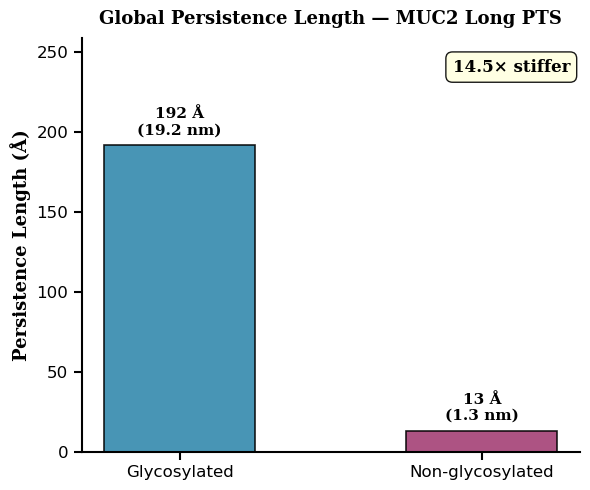

Saved: /home/computer2/analysis_simulations/analysis/persistence_length/plots/persistence_length_bar.png


In [4]:
fig, ax = plt.subplots(figsize=(6, 5), dpi=100)
fig.set_facecolor("white")

systems  = ["Glycosylated", "Non-glycosylated"]
Lp_vals  = [Lp_gly_A,  Lp_nog_A]
Lp_nms   = [Lp_gly_nm, Lp_nog_nm]
colors   = [CLR_GLY,   CLR_NOG]

bars = ax.bar(systems, Lp_vals, color=colors, width=0.5,
              edgecolor="black", linewidth=1.2, alpha=0.88)

for bar, val, nm in zip(bars, Lp_vals, Lp_nms):
    ax.text(bar.get_x() + bar.get_width()/2, val + 5,
            f"{val:.0f} Å\n({nm:.1f} nm)",
            ha="center", va="bottom", fontsize=11,
            fontname="DejaVu Serif", fontweight="bold")

ax.text(0.98, 0.95, f"{ratio:.1f}× stiffer",
        transform=ax.transAxes, fontsize=12,
        fontname="DejaVu Serif", fontweight="bold",
        ha="right", va="top",
        bbox=dict(facecolor="lightyellow", edgecolor="black",
                  boxstyle="round,pad=0.4", alpha=0.9))

ax.set_ylabel("Persistence Length (Å)", fontsize=13,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Global Persistence Length — MUC2 Long PTS",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=10)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=12, length=6, width=1.5, direction="out")
ax.set_ylim(0, max(Lp_vals) * 1.35)

plt.tight_layout()
out = os.path.join(output_dir, "persistence_length_bar.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 3 — Difference in Tangent Correlation (Glyc - NoGlyc)

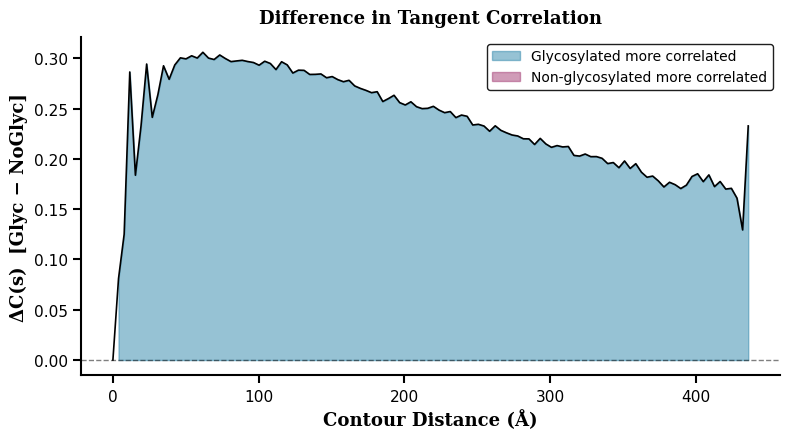

Saved: /home/computer2/analysis_simulations/analysis/persistence_length/plots/tangent_correlation_diff.png


In [5]:
dC = C_gly - C_nog   # glyc minus noglyc at each contour distance

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=100)
fig.set_facecolor("white")

ax.fill_between(s_gly, dC, 0,
                where=(dC > 0), color=CLR_GLY, alpha=0.5,
                label="Glycosylated more correlated")
ax.fill_between(s_gly, dC, 0,
                where=(dC < 0), color=CLR_NOG, alpha=0.5,
                label="Non-glycosylated more correlated")
ax.plot(s_gly, dC, color="black", linewidth=1.2)
ax.axhline(0, color="black", linewidth=1.0, linestyle="--", alpha=0.5)

ax.set_xlabel("Contour Distance (Å)", fontsize=13,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("ΔC(s)  [Glyc − NoGlyc]", fontsize=13,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Difference in Tangent Correlation",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=10)
ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=6, width=1.5, direction="out")

plt.tight_layout()
out = os.path.join(output_dir, "tangent_correlation_diff.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 4 — Sliding Window Persistence Length Along the Chain

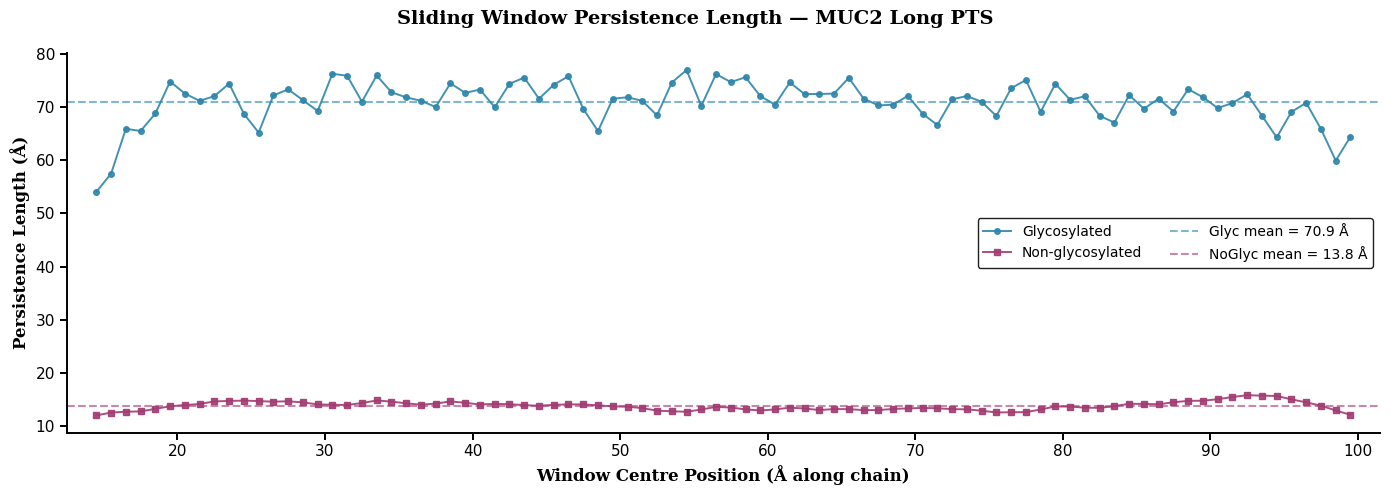

Saved: /home/computer2/analysis_simulations/analysis/persistence_length/plots/lp_sliding_window.png


In [6]:
fig, ax = plt.subplots(figsize=(14, 5), dpi=100)
fig.set_facecolor("white")

ax.plot(win_centre_gly, Lp_win_gly, color=CLR_GLY, linewidth=1.4,
        marker="o", markersize=4, alpha=0.9, label="Glycosylated")
ax.plot(win_centre_nog, Lp_win_nog, color=CLR_NOG, linewidth=1.4,
        marker="s", markersize=4, alpha=0.9, label="Non-glycosylated")
ax.axhline(np.nanmean(Lp_win_gly), color=CLR_GLY, linewidth=1.5,
           linestyle="--", alpha=0.6,
           label=f"Glyc mean = {np.nanmean(Lp_win_gly):.1f} Å")
ax.axhline(np.nanmean(Lp_win_nog), color=CLR_NOG, linewidth=1.5,
           linestyle="--", alpha=0.6,
           label=f"NoGlyc mean = {np.nanmean(Lp_win_nog):.1f} Å")
ax.set_ylabel("Persistence Length (Å)", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_xlabel("Window Centre Position (Å along chain)", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.legend(fontsize=10, framealpha=0.88, edgecolor="black", ncol=2)
ax.set_xlim(win_centre_gly[0] - 2, win_centre_gly[-1] + 2)
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.4)
ax.spines["bottom"].set_linewidth(1.4)
ax.tick_params(labelsize=11, length=5, width=1.4, direction="out")

fig.suptitle("Sliding Window Persistence Length — MUC2 Long PTS",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold")
plt.tight_layout()
out = os.path.join(output_dir, "lp_sliding_window.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 5 — Window-Pair Lp Heatmap (Glycosylated vs Non-glycosylated)

## Figure 6 — Reconstructed C(s) from Each Sliding Window (like Figure 1)

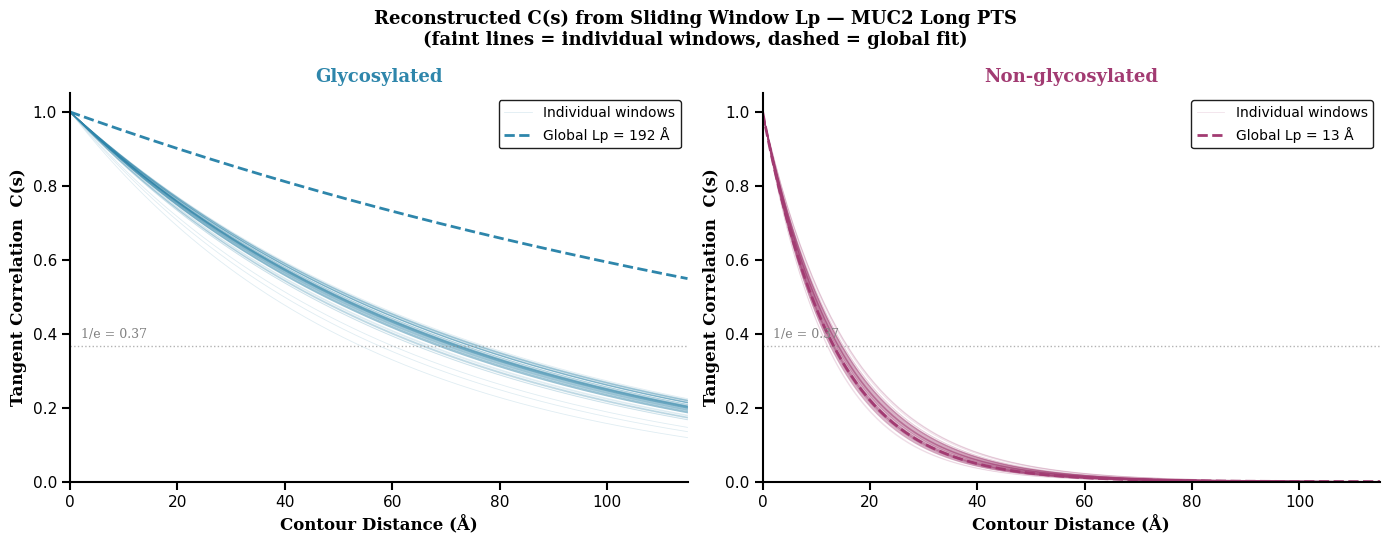

Saved: /home/computer2/analysis_simulations/analysis/persistence_length/plots/window_cs_reconstruction.png


In [7]:
s_win = np.linspace(0, 115, 200)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=100)
fig.set_facecolor("white")

for ax, Lp_arr, sys_label, sys_color, Lp_global in [
    (axes[0], Lp_win_gly, "Glycosylated",    CLR_GLY, Lp_gly_A),
    (axes[1], Lp_win_nog, "Non-glycosylated", CLR_NOG, Lp_nog_A),
]:
    # Individual window curves — thin, transparent
    for i, lp in enumerate(Lp_arr):
        label = "Individual windows" if i == 0 else None
        ax.plot(s_win, np.exp(-s_win / lp),
                color=sys_color, linewidth=0.6, alpha=0.15, label=label)

    # Global Lp curve — dashed for comparison
    ax.plot(s_win, np.exp(-s_win / Lp_global),
            color=sys_color, linewidth=2.0, linestyle="--",
            label=f"Global Lp = {Lp_global:.0f} Å")

    # 1/e reference
    ax.axhline(1/np.e, color="gray", linewidth=1.0, linestyle=":", alpha=0.6)
    ax.text(2, 1/np.e + 0.02, "1/e = 0.37", fontsize=9,
            fontname="DejaVu Serif", color="gray")
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.3)

    ax.set_xlabel("Contour Distance (Å)", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Tangent Correlation  C(s)", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(sys_label, fontsize=13, fontname="DejaVu Serif",
                 fontweight="bold", color=sys_color, pad=8)
    ax.set_xlim(0, 115)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)
    ax.tick_params(labelsize=11, length=6, width=1.5, direction="out")
    ax.xaxis.set_major_locator(ticker.MultipleLocator(20))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(0.2))

fig.suptitle("Reconstructed C(s) from Sliding Window Lp — MUC2 Long PTS\n"
             "(faint lines = individual windows, dashed = global fit)",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold")
plt.tight_layout()
out = os.path.join(output_dir, "window_cs_reconstruction.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 7 — Reconstructed C(s) Extended to 400 Å (Extrapolated Beyond Chain Length)

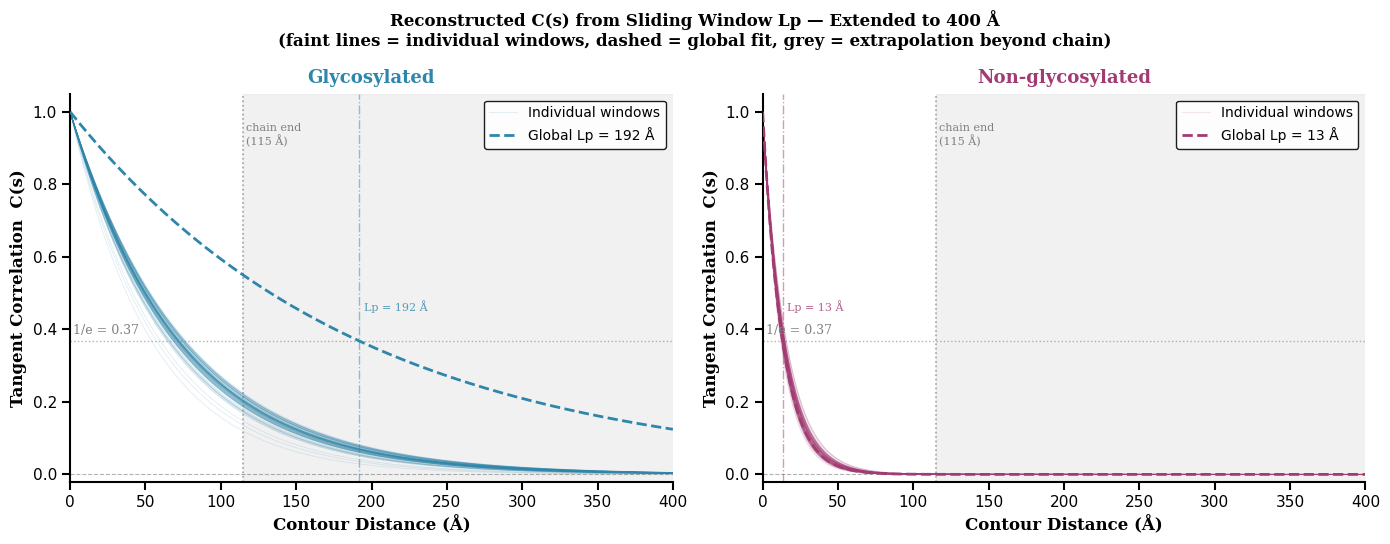

Saved: /home/computer2/analysis_simulations/analysis/persistence_length/plots/window_cs_reconstruction_400A.png


In [8]:
chain_len_A = s_gly[-1]        # actual chain length (~440 Å for 115 residues)
s_ext = np.linspace(0, 400, 500)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=100)
fig.set_facecolor("white")

for ax, Lp_arr, sys_label, sys_color, Lp_global in [
    (axes[0], Lp_win_gly, "Glycosylated",     CLR_GLY, Lp_gly_A),
    (axes[1], Lp_win_nog, "Non-glycosylated",  CLR_NOG, Lp_nog_A),
]:
    # Shaded region beyond actual chain length
    ax.axvspan(115, 400, color="lightgray", alpha=0.30, zorder=0)
    ax.axvline(115, color="gray", linewidth=1.2, linestyle=":", alpha=0.7, zorder=1)
    ax.text(117, 0.97, "chain end\n(115 Å)", fontsize=8,
            fontname="DejaVu Serif", color="gray", va="top")

    # Individual window curves — thin, transparent, extended
    for i, lp in enumerate(Lp_arr):
        label = "Individual windows" if i == 0 else None
        ax.plot(s_ext, np.exp(-s_ext / lp),
                color=sys_color, linewidth=0.6, alpha=0.15, label=label, zorder=2)

    # Global Lp curve — dashed, extended
    ax.plot(s_ext, np.exp(-s_ext / Lp_global),
            color=sys_color, linewidth=2.0, linestyle="--", zorder=3,
            label=f"Global Lp = {Lp_global:.0f} Å")

    # 1/e reference line
    ax.axhline(1/np.e, color="gray", linewidth=1.0, linestyle=":", alpha=0.6, zorder=1)
    ax.text(2, 1/np.e + 0.02, "1/e = 0.37", fontsize=9,
            fontname="DejaVu Serif", color="gray")
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.3, zorder=1)

    # Mark where global Lp curve crosses 1/e (i.e. at s = Lp_global)
    if Lp_global <= 400:
        ax.axvline(Lp_global, color=sys_color, linewidth=1.0, linestyle="-.", alpha=0.5)
        ax.text(Lp_global + 3, 0.45, f"Lp = {Lp_global:.0f} Å",
                fontsize=8, fontname="DejaVu Serif", color=sys_color, alpha=0.8)

    ax.set_xlabel("Contour Distance (Å)", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Tangent Correlation  C(s)", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(sys_label, fontsize=13, fontname="DejaVu Serif",
                 fontweight="bold", color=sys_color, pad=8)
    ax.set_xlim(0, 400)
    ax.set_ylim(-0.02, 1.05)
    ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)
    ax.tick_params(labelsize=11, length=6, width=1.5, direction="out")
    ax.xaxis.set_major_locator(ticker.MultipleLocator(50))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(0.2))

fig.suptitle("Reconstructed C(s) from Sliding Window Lp — Extended to 400 Å\n"
             "(faint lines = individual windows, dashed = global fit, grey = extrapolation beyond chain)",
             fontsize=12, fontname="DejaVu Serif", fontweight="bold")
plt.tight_layout()
out = os.path.join(output_dir, "window_cs_reconstruction_400A.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

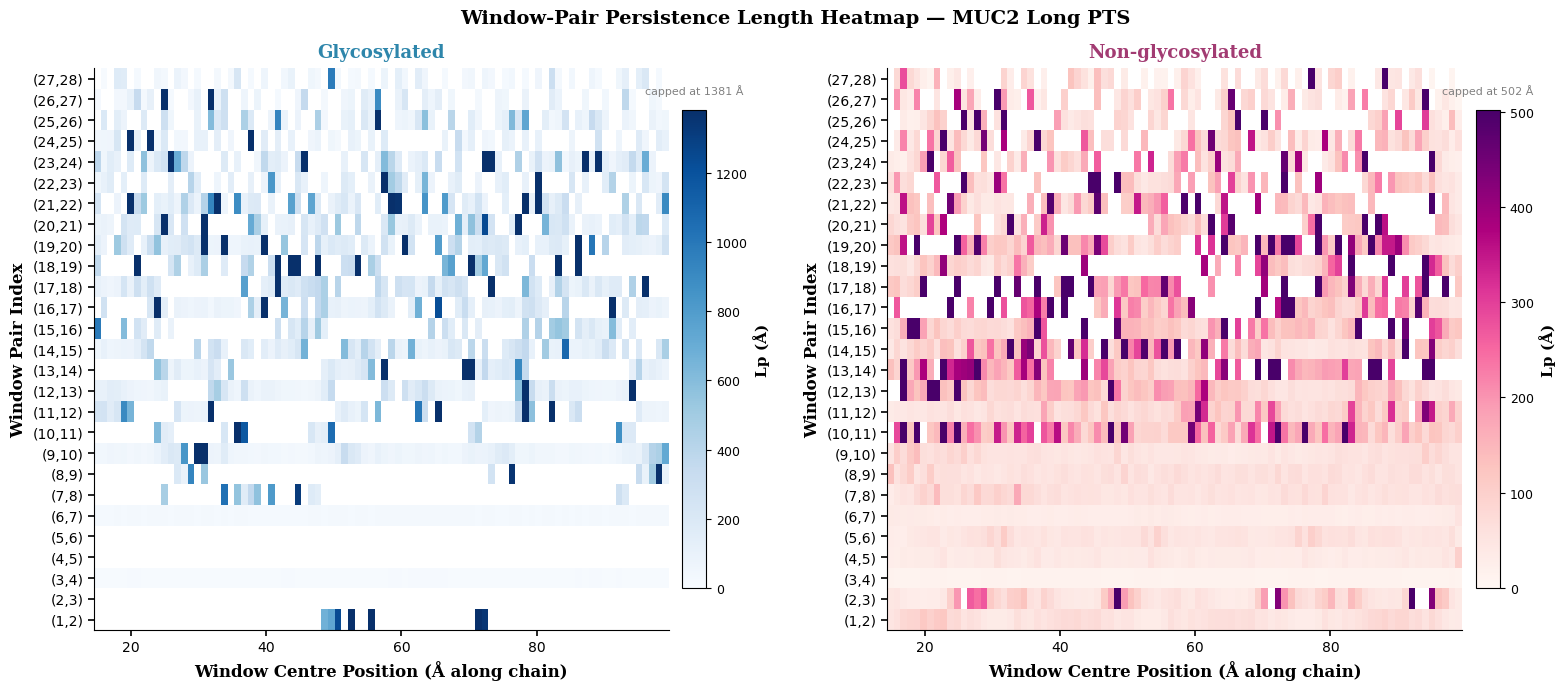

Saved: /home/computer2/analysis_simulations/analysis/persistence_length/plots/lp_window_pairs_heatmap.png


In [9]:
wp_gly = np.genfromtxt(base + "lp_window_pairs_glycans.dat",   comments="#")
wp_nog = np.genfromtxt(base + "lp_window_pairs_noglycans.dat", comments="#")

# chain positions and pair labels
chain_pos  = wp_gly[:, 1]                       # window centre (Å along chain)
lp_gly_mat = wp_gly[:, 2:]                      # (86, 27)
lp_nog_mat = wp_nog[:, 2:]

pair_labels = [f"({i},{i+1})" for i in range(1, 28)]  # (1,2) … (27,28)

# Cap at 95th percentile to suppress extreme outlier fits
cap_gly = np.nanpercentile(lp_gly_mat, 95)
cap_nog = np.nanpercentile(lp_nog_mat, 95)
lp_gly_capped = np.where(lp_gly_mat > cap_gly, cap_gly, lp_gly_mat)
lp_nog_capped = np.where(lp_nog_mat > cap_nog, cap_nog, lp_nog_mat)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=100)
fig.set_facecolor("white")

for ax, mat, title, cmap, cap in [
    (axes[0], lp_gly_capped, "Glycosylated",    "Blues",  cap_gly),
    (axes[1], lp_nog_capped, "Non-glycosylated", "RdPu",   cap_nog),
]:
    im = ax.imshow(mat.T, aspect="auto", origin="lower",
                   cmap=cmap, vmin=0, vmax=cap,
                   extent=[chain_pos[0], chain_pos[-1], 0.5, 27.5])
    cbar = plt.colorbar(im, ax=ax, pad=0.02, shrink=0.85)
    cbar.set_label("Lp (Å)", fontsize=11, fontname="DejaVu Serif", fontweight="bold")
    cbar.ax.tick_params(labelsize=9)
    cbar.ax.text(0.5, 1.03, f"capped at {cap:.0f} Å",
                 transform=cbar.ax.transAxes, fontsize=8,
                 ha="center", va="bottom", color="gray")

    ax.set_xlabel("Window Centre Position (Å along chain)", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Window Pair Index", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_yticks(range(1, 28))
    ax.set_yticklabels(pair_labels, fontsize=7)
    ax.set_title(title, fontsize=13, fontname="DejaVu Serif",
                 fontweight="bold", color=CLR_GLY if "Glyc" in title else CLR_NOG,
                 pad=8)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(20))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=10, length=4, width=1.2, direction="out")

fig.suptitle("Window-Pair Persistence Length Heatmap — MUC2 Long PTS",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold")
plt.tight_layout()
out = os.path.join(output_dir, "lp_window_pairs_heatmap.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

---
## Three-System Comparison — Including Ext. Glycosylated

In [10]:
CLR_EXT  = "#F18F01"
base_ext = "/home/computer2/analysis_simulations/analysis/persistence_length_xglyc/"

# Load ext_glycans sliding window
sw_ext = np.genfromtxt(base_ext + "lp_sliding_window_xglyc.dat", comments="#")
# cols: window_start  window_centre  Lp_A  Lp_nm  R2
win_centre_ext = sw_ext[:, 1]
Lp_win_ext     = sw_ext[:, 2]
R2_win_ext     = sw_ext[:, 4]

# Global Lp values (all three systems)
Lp_gly_A  = 191.952;  Lp_gly_nm  = 19.195
Lp_nog_A  =  13.206;  Lp_nog_nm  =  1.321
Lp_ext_A  = 293.378;  Lp_ext_nm  = 29.338

print(f"Glycosylated     Lp = {Lp_gly_A:.1f} Å  ({Lp_gly_nm:.2f} nm)")
print(f"Non-glycosylated Lp = {Lp_nog_A:.1f} Å  ({Lp_nog_nm:.2f} nm)")
print(f"Ext. Glycosylated Lp = {Lp_ext_A:.1f} Å  ({Lp_ext_nm:.2f} nm)")
print(f"\nSliding window means:")
print(f"  Glycosylated     : {np.nanmean(Lp_win_gly):.1f} ± {np.nanstd(Lp_win_gly):.1f} Å")
print(f"  Non-glycosylated : {np.nanmean(Lp_win_nog):.1f} ± {np.nanstd(Lp_win_nog):.1f} Å")
print(f"  Ext. Glycosylated: {np.nanmean(Lp_win_ext):.1f} ± {np.nanstd(Lp_win_ext):.1f} Å")

Glycosylated     Lp = 192.0 Å  (19.20 nm)
Non-glycosylated Lp = 13.2 Å  (1.32 nm)
Ext. Glycosylated Lp = 293.4 Å  (29.34 nm)

Sliding window means:
  Glycosylated     : 70.9 ± 3.9 Å
  Non-glycosylated : 13.8 ± 0.8 Å
  Ext. Glycosylated: 121.9 ± 13.0 Å


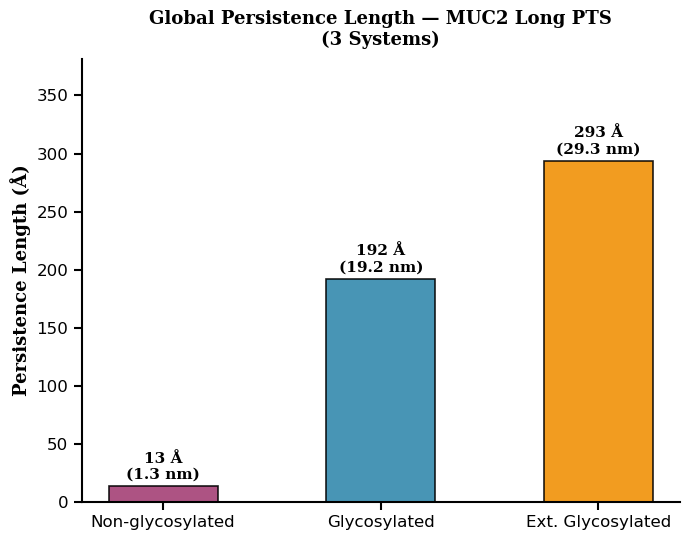

Saved: /home/computer2/analysis_simulations/analysis/persistence_length/plots/persistence_length_bar_3sys.png


In [11]:
# ── Figure: Global Lp bar chart — all 3 systems ──────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5.5), dpi=100)
fig.set_facecolor("white")

systems = ["Non-glycosylated", "Glycosylated", "Ext. Glycosylated"]
Lp_vals = [Lp_nog_A,          Lp_gly_A,       Lp_ext_A]
Lp_nms  = [Lp_nog_nm,         Lp_gly_nm,      Lp_ext_nm]
colors  = [CLR_NOG,            CLR_GLY,         CLR_EXT]

bars = ax.bar(systems, Lp_vals, color=colors, width=0.5,
              edgecolor="black", linewidth=1.2, alpha=0.88)

for bar, val, nm in zip(bars, Lp_vals, Lp_nms):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 4,
            f"{val:.0f} Å\n({nm:.1f} nm)",
            ha="center", va="bottom", fontsize=11,
            fontname="DejaVu Serif", fontweight="bold")

ax.set_ylabel("Persistence Length (Å)", fontsize=13,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Global Persistence Length — MUC2 Long PTS\n(3 Systems)",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=10)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=12, length=6, width=1.5, direction="out")
ax.set_ylim(0, max(Lp_vals) * 1.30)

plt.tight_layout()
out = os.path.join(output_dir, "persistence_length_bar_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

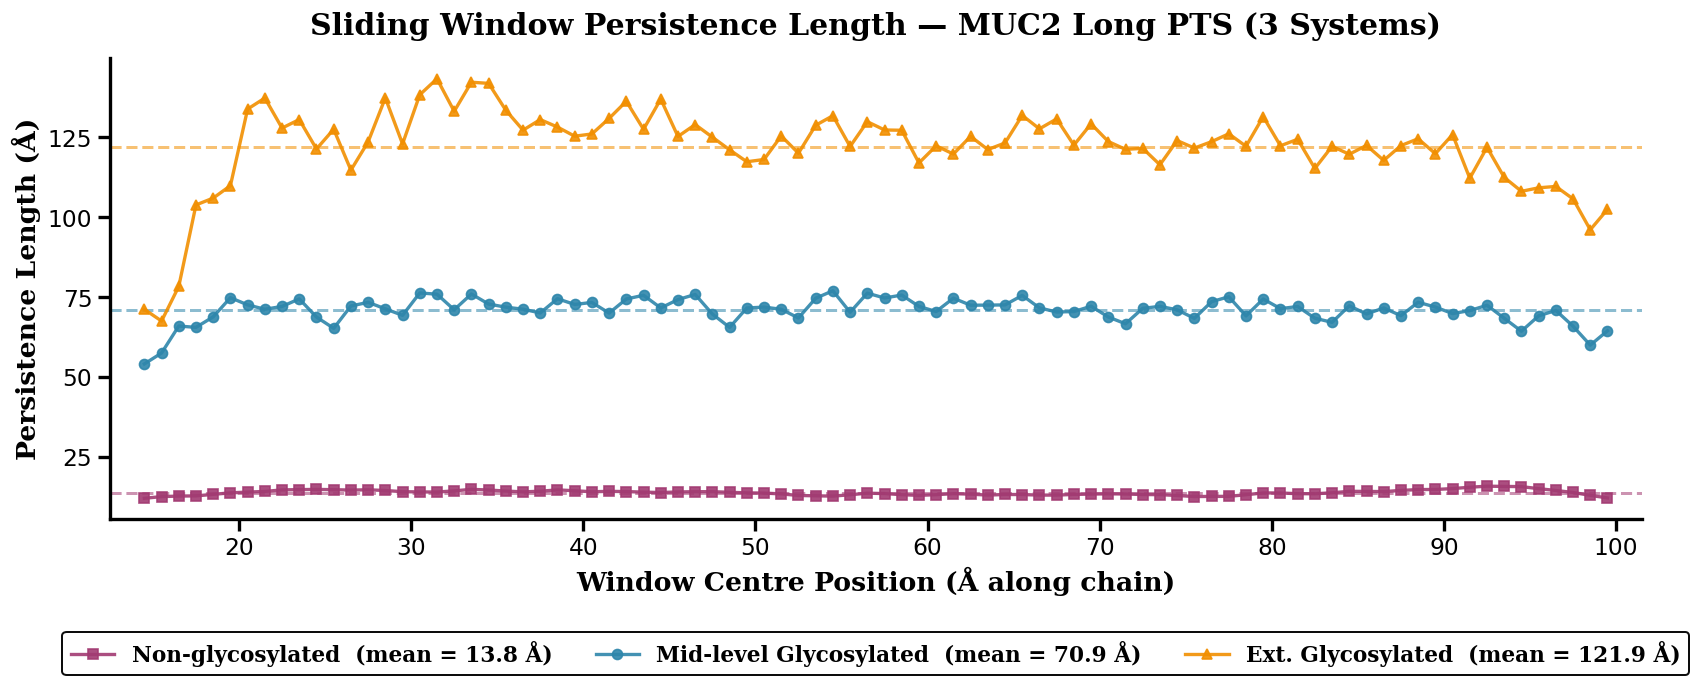

Saved: /home/computer2/analysis_simulations/analysis/persistence_length/plots/lp_sliding_window_3sys.png


In [12]:
# ── Figure: Sliding window Lp — all 3 systems ────────────────────────────────
fig, ax = plt.subplots(figsize=(15, 6), dpi=120)
fig.set_facecolor("white")

# Canonical order: Non-glycosylated -> Mid-level Glycosylated -> Ext. Glycosylated
sys_info = [
    (win_centre_nog, Lp_win_nog, CLR_NOG, "s",
     f"Non-glycosylated  (mean = {np.nanmean(Lp_win_nog):.1f} \u00c5)"),
    (win_centre_gly, Lp_win_gly, CLR_GLY, "o",
     f"Mid-level Glycosylated  (mean = {np.nanmean(Lp_win_gly):.1f} \u00c5)"),
    (win_centre_ext, Lp_win_ext, CLR_EXT, "^",
     f"Ext. Glycosylated  (mean = {np.nanmean(Lp_win_ext):.1f} \u00c5)"),
]

for wc, lp, clr, mkr, lbl in sys_info:
    ax.plot(wc, lp, color=clr, linewidth=2.0,
            marker=mkr, markersize=6, alpha=0.9, label=lbl)
    ax.axhline(np.nanmean(lp), color=clr, linewidth=1.8,
               linestyle="--", alpha=0.55)

ax.set_ylabel("Persistence Length (\u00c5)", fontsize=16,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_xlabel("Window Centre Position (\u00c5 along chain)", fontsize=16,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Sliding Window Persistence Length \u2014 MUC2 Long PTS (3 Systems)",
             fontsize=18, fontname="DejaVu Serif", fontweight="bold", pad=14)
leg = ax.legend(fontsize=13, framealpha=0.95, edgecolor="black", ncol=3,
                loc="upper center", bbox_to_anchor=(0.5, -0.22),
                prop={"family": "DejaVu Serif", "size": 13, "weight": "bold"})
leg.get_frame().set_linewidth(1.2)
ax.set_xlim(win_centre_nog[0] - 2, win_centre_nog[-1] + 2)
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2.0)
ax.spines["bottom"].set_linewidth(2.0)
ax.tick_params(labelsize=14, length=7, width=2.0, direction="out")
ax.yaxis.set_major_locator(ticker.MaxNLocator(6))

plt.tight_layout()
out = os.path.join(output_dir, "lp_sliding_window_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")


### Figure: Reconstructed C(s) — All 3 Systems

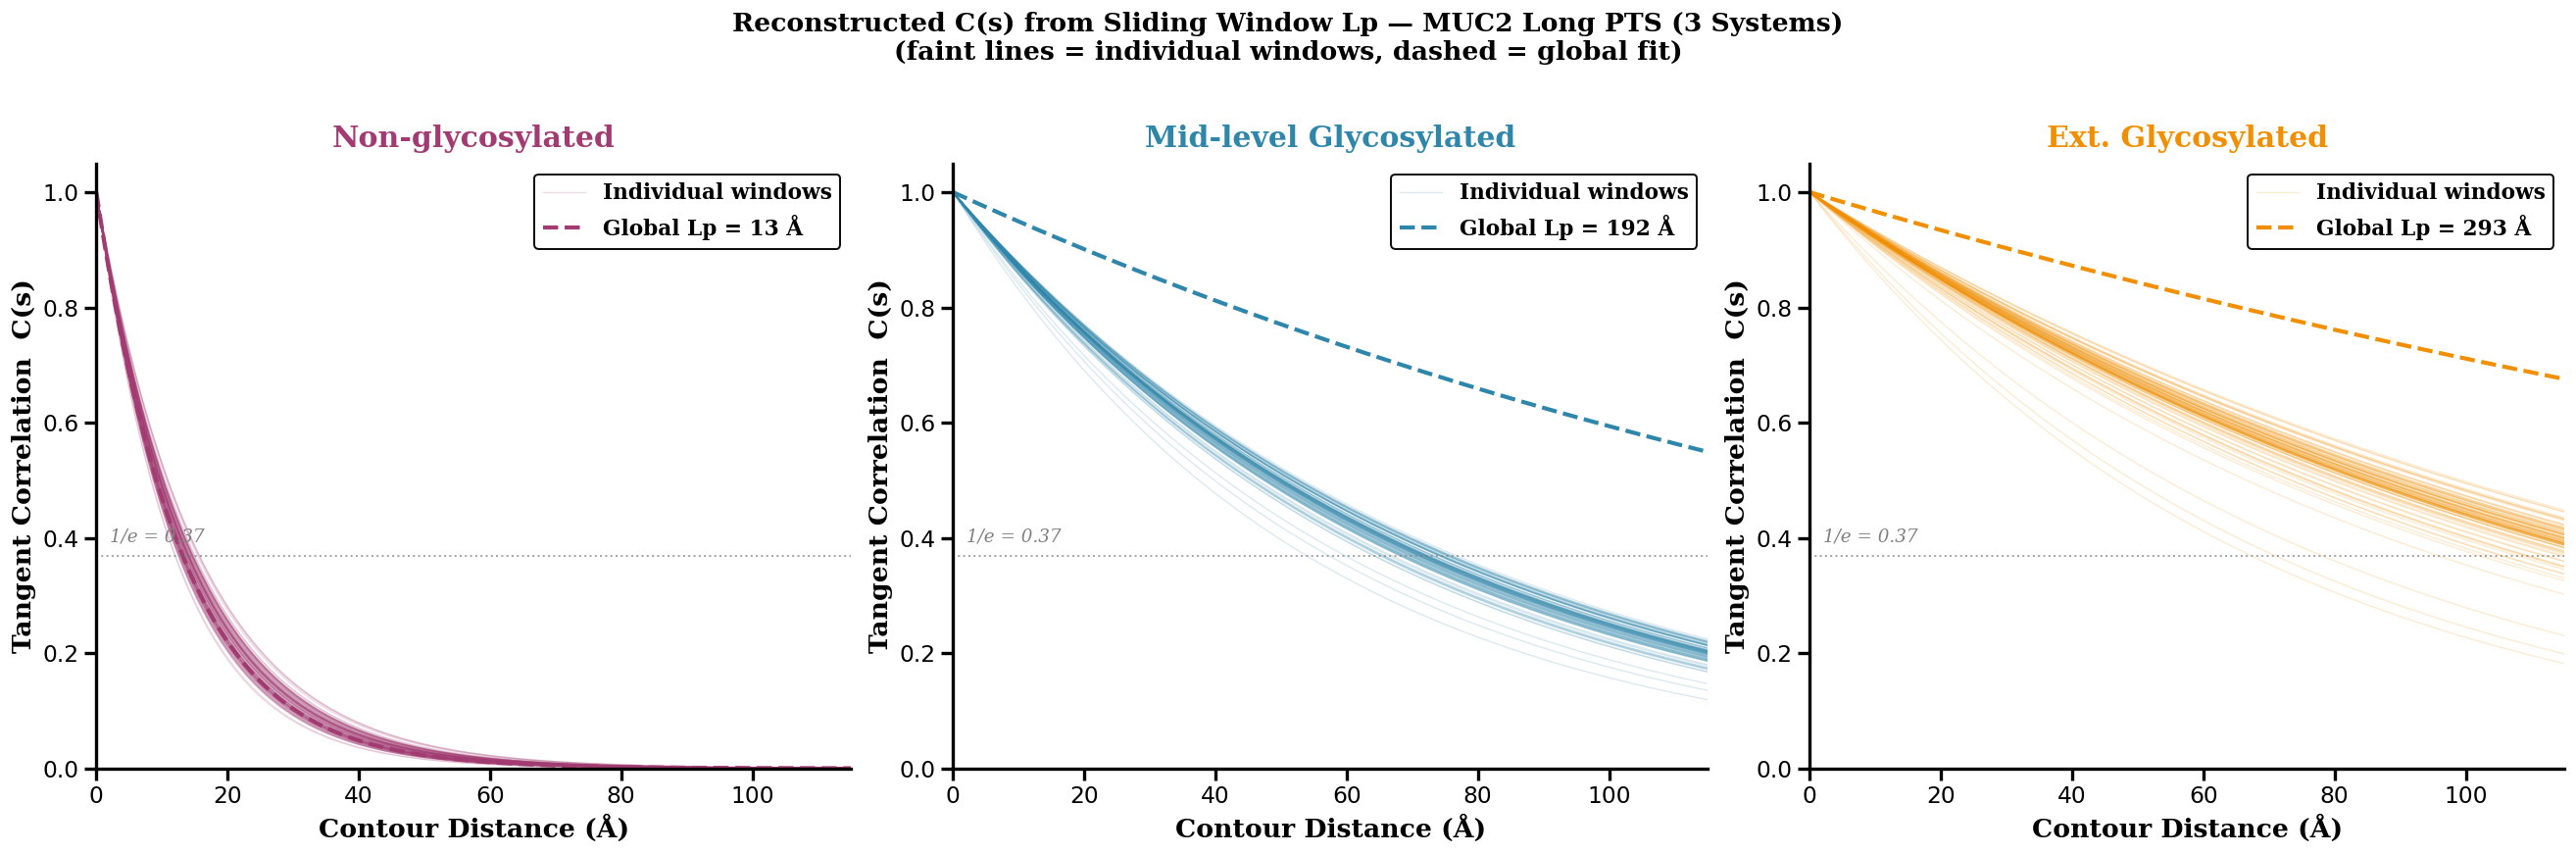

Saved: /home/computer2/analysis_simulations/analysis/persistence_length/plots/window_cs_reconstruction_3sys.png


In [13]:
s_win = np.linspace(0, 115, 200)

fig, axes = plt.subplots(1, 3, figsize=(22, 7), dpi=120)
fig.set_facecolor("white")

# Canonical order: Non-glycosylated -> Mid-level Glycosylated -> Ext. Glycosylated
panels = [
    (axes[0], Lp_win_nog, "Non-glycosylated",      CLR_NOG, Lp_nog_A),
    (axes[1], Lp_win_gly, "Mid-level Glycosylated", CLR_GLY, Lp_gly_A),
    (axes[2], Lp_win_ext, "Ext. Glycosylated",      CLR_EXT, Lp_ext_A),
]

for ax, Lp_arr, sys_label, sys_color, Lp_global in panels:
    for i, lp in enumerate(Lp_arr):
        label = "Individual windows" if i == 0 else None
        ax.plot(s_win, np.exp(-s_win / lp),
                color=sys_color, linewidth=0.8, alpha=0.18, label=label)

    ax.plot(s_win, np.exp(-s_win / Lp_global),
            color=sys_color, linewidth=2.5, linestyle="--",
            label=f"Global Lp = {Lp_global:.0f} \u00c5")

    ax.axhline(1/np.e, color="gray", linewidth=1.2, linestyle=":", alpha=0.7)
    ax.text(2, 1/np.e + 0.025, "1/e = 0.37", fontsize=11,
            fontname="DejaVu Serif", color="gray", fontstyle="italic")
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.3)

    ax.set_xlabel("Contour Distance (\u00c5)", fontsize=16,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Tangent Correlation  C(s)", fontsize=16,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(sys_label, fontsize=18, fontname="DejaVu Serif",
                 fontweight="bold", color=sys_color, pad=10)
    ax.set_xlim(0, 115)
    ax.set_ylim(0, 1.05)
    leg = ax.legend(fontsize=13, framealpha=0.95, edgecolor="black",
                    prop={"family": "DejaVu Serif", "size": 13, "weight": "bold"})
    leg.get_frame().set_linewidth(1.2)
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(2.0)
    ax.spines["bottom"].set_linewidth(2.0)
    ax.tick_params(labelsize=14, length=7, width=2.0, direction="out")
    ax.xaxis.set_major_locator(ticker.MultipleLocator(20))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(0.2))

fig.suptitle(
    "Reconstructed C(s) from Sliding Window Lp \u2014 MUC2 Long PTS (3 Systems)\n"
    "(faint lines = individual windows, dashed = global fit)",
    fontsize=16, fontname="DejaVu Serif", fontweight="bold", y=1.03)
plt.tight_layout()
out = os.path.join(output_dir, "window_cs_reconstruction_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")


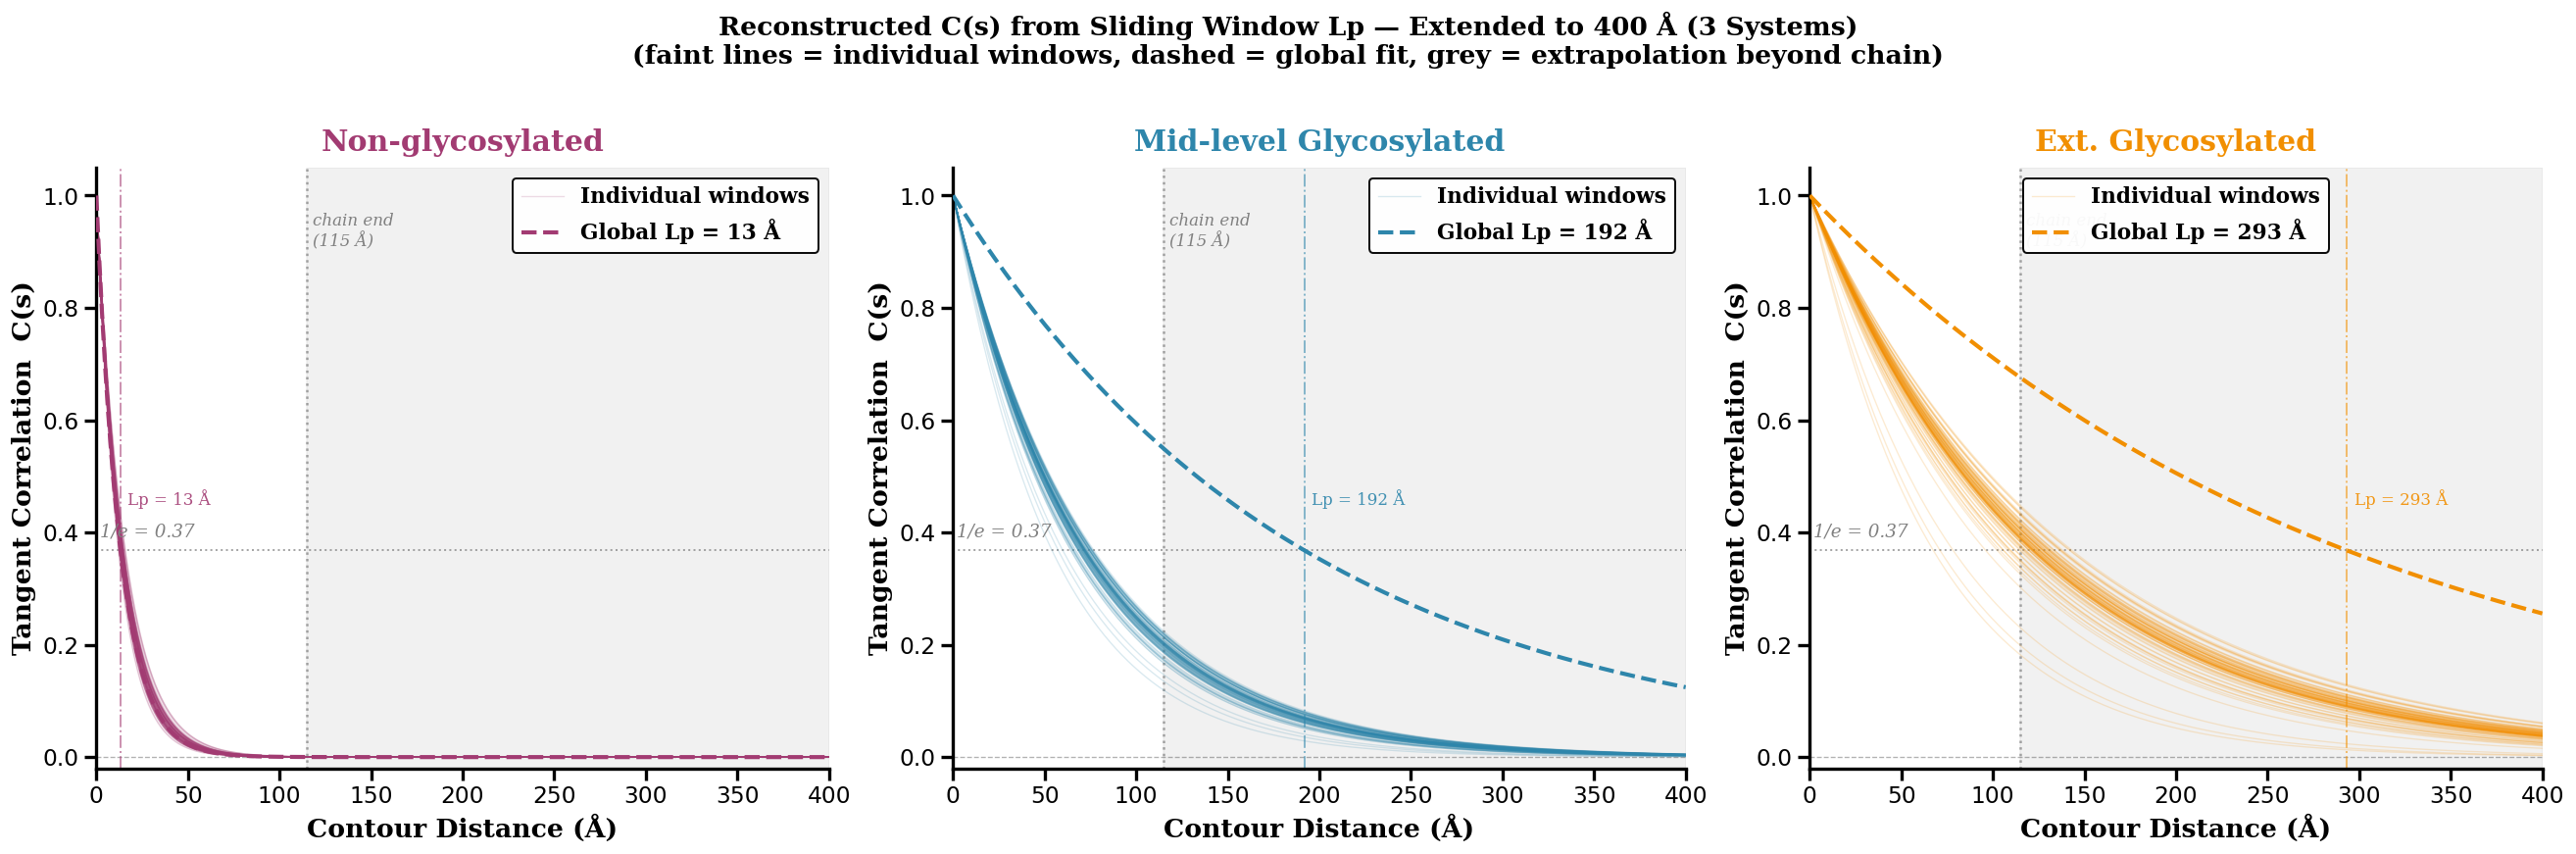

Saved: /home/computer2/analysis_simulations/analysis/persistence_length/plots/window_cs_reconstruction_400A_3sys.png


In [14]:
s_ext = np.linspace(0, 400, 500)

fig, axes = plt.subplots(1, 3, figsize=(22, 7), dpi=120)
fig.set_facecolor("white")

# Canonical order: Non-glycosylated -> Mid-level Glycosylated -> Ext. Glycosylated
panels = [
    (axes[0], Lp_win_nog, "Non-glycosylated",      CLR_NOG, Lp_nog_A),
    (axes[1], Lp_win_gly, "Mid-level Glycosylated", CLR_GLY, Lp_gly_A),
    (axes[2], Lp_win_ext, "Ext. Glycosylated",      CLR_EXT, Lp_ext_A),
]

for ax, Lp_arr, sys_label, sys_color, Lp_global in panels:
    ax.axvspan(115, 400, color="lightgray", alpha=0.30, zorder=0)
    ax.axvline(115, color="gray", linewidth=1.5, linestyle=":", alpha=0.7, zorder=1)
    ax.text(118, 0.97, "chain end\n(115 \u00c5)", fontsize=10,
            fontname="DejaVu Serif", color="gray", va="top", fontstyle="italic")

    for i, lp in enumerate(Lp_arr):
        label = "Individual windows" if i == 0 else None
        ax.plot(s_ext, np.exp(-s_ext / lp),
                color=sys_color, linewidth=0.8, alpha=0.18, label=label, zorder=2)

    ax.plot(s_ext, np.exp(-s_ext / Lp_global),
            color=sys_color, linewidth=2.5, linestyle="--", zorder=3,
            label=f"Global Lp = {Lp_global:.0f} \u00c5")

    ax.axhline(1/np.e, color="gray", linewidth=1.2, linestyle=":", alpha=0.7, zorder=1)
    ax.text(2, 1/np.e + 0.025, "1/e = 0.37", fontsize=11,
            fontname="DejaVu Serif", color="gray", fontstyle="italic")
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.3, zorder=1)

    if Lp_global <= 400:
        ax.axvline(Lp_global, color=sys_color, linewidth=1.2,
                   linestyle="-.", alpha=0.55, zorder=2)
        ax.text(Lp_global + 4, 0.45, f"Lp = {Lp_global:.0f} \u00c5",
                fontsize=10, fontname="DejaVu Serif", color=sys_color, alpha=0.9)

    ax.set_xlabel("Contour Distance (\u00c5)", fontsize=16,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Tangent Correlation  C(s)", fontsize=16,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(sys_label, fontsize=18, fontname="DejaVu Serif",
                 fontweight="bold", color=sys_color, pad=10)
    ax.set_xlim(0, 400)
    ax.set_ylim(-0.02, 1.05)
    leg = ax.legend(fontsize=13, framealpha=0.95, edgecolor="black",
                    prop={"family": "DejaVu Serif", "size": 13, "weight": "bold"})
    leg.get_frame().set_linewidth(1.2)
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(2.0)
    ax.spines["bottom"].set_linewidth(2.0)
    ax.tick_params(labelsize=14, length=7, width=2.0, direction="out")
    ax.xaxis.set_major_locator(ticker.MultipleLocator(50))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(0.2))

fig.suptitle(
    "Reconstructed C(s) from Sliding Window Lp \u2014 Extended to 400 \u00c5 (3 Systems)\n"
    "(faint lines = individual windows, dashed = global fit, grey = extrapolation beyond chain)",
    fontsize=16, fontname="DejaVu Serif", fontweight="bold", y=1.03)
plt.tight_layout()
out = os.path.join(output_dir, "window_cs_reconstruction_400A_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")
